# 00 · Análisis estructural y variable objetivo

**Proyecto 3 · Minería de Datos (ISW-911) · Grupo Innova S.A.**  
**Responsable:** Joshua Quesada  
**Rama de trabajo:** `feature/joshua-target`  
**Criterio de la rúbrica:** 1. EDA y Preparación (10 %)

> Describir el dataset (dimensiones, tipos, cardinalidad) y justificar técnicamente el target `flete` como problema de REGRESIÓN.

_Regla: no borrar celdas de otros, documentar CADA decisión en Markdown (qué se hizo, por qué y qué alternativa se descartó)._

In [1]:
import sys
sys.path.append("..")  # para importar src/ desde notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.datos import cargar_datos, dividir_train_test

sns.set_theme(style="whitegrid")
df = cargar_datos()
X_train, X_test, y_train, y_test = dividir_train_test(df)
print("Datos:", df.shape, "| Train:", X_train.shape, "| Test:", X_test.shape)

Datos: (110196, 27) | Train: (88156, 11) | Test: (22040, 11)


## 1. Dimensiones y tipos de datos

Tras quitar las 2 454 órdenes no entregadas (sin `fecha_entrega`), el conjunto tiene
**110 196 filas y 27 columnas** (las 25 originales + `volumen_cm3` y `mismo_estado`).
Cada fila es un **ítem vendido** dentro de una orden.

- **Numéricas:** precio, flete, medidas y peso del producto, fotos, cuotas, pago, reseña y las 2 variables creadas.
- **Categóricas:** estado de la orden, categoría del producto, ciudad/estado del cliente y del vendedor, tipo de pago.
- **Fechas:** 3 columnas guardadas como texto; no se usan como predictoras porque la fecha de entrega
  ocurre después de la compra (fuga de información).
- Los **códigos postales** son números, pero representan zonas, no cantidades.

In [2]:
print("Filas:", df.shape[0], "| Columnas:", df.shape[1])

# Clasificación de columnas por tipo
fechas = ["fecha_compra", "fecha_entrega", "fecha_entrega_estimada"]
numericas = df.select_dtypes(include="number").columns.tolist()
categoricas = [c for c in df.select_dtypes(exclude="number").columns if c not in fechas]

print("Numéricas:", len(numericas))
print("Categóricas (texto):", len(categoricas))
print("Fechas (guardadas como texto):", len(fechas))

df.info()

Filas: 110196 | Columnas: 27
Numéricas: 17
Categóricas (texto): 7
Fechas (guardadas como texto): 3
<class 'pandas.DataFrame'>
RangeIndex: 110196 entries, 0 to 110195
Data columns (total 27 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   numero_item                 110196 non-null  int64  
 1   precio                      110196 non-null  float64
 2   flete                       110196 non-null  float64
 3   estado_orden                110196 non-null  str    
 4   fecha_compra                110196 non-null  str    
 5   fecha_entrega               110196 non-null  str    
 6   fecha_entrega_estimada      110196 non-null  str    
 7   largo_nombre_producto       108659 non-null  float64
 8   largo_descripcion_producto  108659 non-null  float64
 9   cantidad_fotos              108659 non-null  float64
 10  peso_g                      110178 non-null  float64
 11  largo_cm                    110178 non-nul

## 2. Cardinalidad

La cardinalidad (cantidad de valores distintos) decide cómo se codifica cada variable categórica:

| Variable | Valores distintos | Decisión |
|---|---|---|
| `estado_vendedor` / `estado_cliente` | 22 / 27 | Se usan: One-Hot (modelo lineal) u Ordinal (árboles) |
| `categoria_producto` | 71 | Se usa, con la misma codificación |
| `ciudad_vendedor` / `ciudad_cliente` | 595 / 4 085 | Se descartan: demasiadas columnas y la ubicación ya está en el estado |
| Códigos postales | 2 168 / 14 889 | Se descartan: son identificadores de zona, no cantidades |
| `estado_orden` | 2 | Se descarta: casi todo es `delivered` y no aporta información |

Las numéricas con muchos valores (peso, precio, volumen) se usan como continuas.

In [3]:
cardinalidad = df.nunique().sort_values().to_frame("valores_distintos")
cardinalidad["tipo"] = df.dtypes.astype(str)
cardinalidad

,valores_distintos,tipo
estado_orden,2,str
mismo_estado,2,int64
tipo_pago,4,str
calificacion_resena,5,float64
cantidad_fotos,19,float64
numero_item,21,int64
estado_vendedor,22,str
cuotas_pago,24,float64
estado_cliente,27,str
largo_nombre_producto,65,float64


## 3. Variable objetivo: `flete`

**Qué es:** el costo de envío de cada ítem vendido.

**Distribución:** mediana de 16.26 y media de 19.95. La mitad de los fletes está entre 13.08 y 21.15,
pero la cola derecha es larga (asimetría 5.66; el 1 % supera 83.8 y el máximo es 409.68).
En escala logarítmica la distribución se ve casi simétrica.
Hay **381 fletes en 0** (envío gratis): son casos reales y se conservan.

**Por qué es un problema de regresión:** `flete` es una variable **numérica continua**, así que
el objetivo es predecir un monto y no una categoría. Por eso se usan modelos de regresión y se evalúan
con **RMSE, MAE y R²**. Si el objetivo fuera, por ejemplo, "¿llegó a tiempo? sí/no", sería clasificación.

**Por qué importa al negocio:** el flete equivale, en la mediana, a cerca del **23 % del precio** del producto.
Estimarlo bien permite mostrar al cliente un costo de envío confiable antes de pagar, negociar tarifas
con las transportistas y detectar qué productos o rutas encarecen la venta.

count    110196.00
mean         19.95
std          15.70
min           0.00
25%          13.08
50%          16.26
75%          21.15
max         409.68
Name: flete, dtype: float64
Asimetría: 5.66
Fletes en 0 (envío gratis): 381
Percentil 95: 45.09 | Percentil 99: 83.83


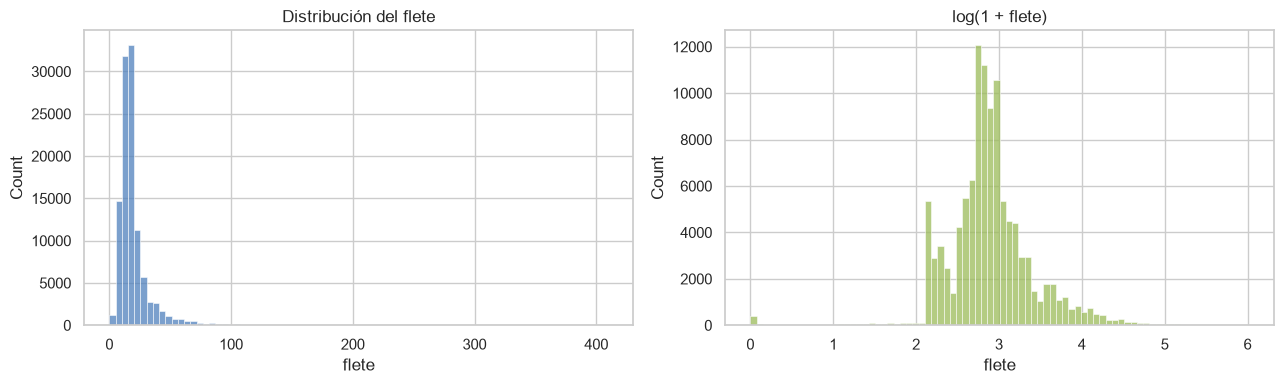

In [4]:
print(df["flete"].describe().round(2))
print("Asimetría:", round(df["flete"].skew(), 2))
print("Fletes en 0 (envío gratis):", (df["flete"] == 0).sum())
print("Percentil 95:", df["flete"].quantile(0.95), "| Percentil 99:", df["flete"].quantile(0.99))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["flete"], bins=80, ax=ax[0], color="#4F81BD")
ax[0].set_title("Distribución del flete")
sns.histplot(np.log1p(df["flete"]), bins=80, ax=ax[1], color="#9BBB59")
ax[1].set_title("log(1 + flete)")
plt.tight_layout()
plt.show()

En el gráfico logarítmico se ve una barra aislada en 0: son los 381 envíos gratis.
La distribución tampoco es una sola campana: tiene varios picos (cerca de 2.5 y de 3),
lo que sugiere **tarifas por tramos** de las transportistas (por rango de peso o de distancia).
Esto favorece a los modelos de árboles, que capturan saltos mejor que una recta.

## 4. Variables excluidas por fuga de información

El modelo debe predecir el flete **en el momento de la compra**. Por eso solo se usan variables que
ya se conocen en ese momento. Usar otras sería *data leakage*: el modelo se vería muy bueno en las
pruebas y fallaría en la realidad.

| Variable | Por qué se excluye |
|---|---|
| `valor_pago` | El pago de la orden **ya incluye el flete**: sería darle la respuesta al modelo |
| `fecha_entrega`, `dias_entrega`, `entregado_a_tiempo` | Se conocen **después** de la entrega |
| `calificacion_resena` | El cliente califica **después** de recibir el producto |

**Predictores finales (11):** `peso_g`, `largo_cm`, `alto_cm`, `ancho_cm`, `volumen_cm3`, `precio`,
`numero_item`, `mismo_estado`, `categoria_producto`, `estado_cliente` y `estado_vendedor`.

In [5]:
config.EXCLUIDAS_POR_FUGA

['valor_pago',
 'fecha_entrega',
 'dias_entrega',
 'entregado_a_tiempo',
 'calificacion_resena']

| `fecha_entrega` (y `dias_entrega`, `entregado_a_tiempo`, creadas en el Lab 4) | Se conocen **después** de la entrega |

## Conclusiones

## Conclusiones

- El conjunto tiene 110 196 ítems entregados y 27 columnas; cada fila es un ítem vendido.
- El target es `flete`, una variable continua y asimétrica → **problema de regresión** (RMSE, MAE, R²).
- Las categóricas de baja cardinalidad (estados y categoría) se codifican; ciudades y códigos postales se descartan.
- Se excluyen `valor_pago`, fechas de entrega y reseña para evitar fuga de información.
- Se crearon `volumen_cm3` y `mismo_estado`, porque el envío se cobra por tamaño, peso y distancia.